# What does the CNN look at? Grad-CAM heatmaps

Grad-CAM [Selvaraju et al., ICCV 2017] shows which parts of an image a CNN's decision depended on.
It takes the gradient of the predicted class score with respect to the last convolutional feature maps (here the 8×8×128 output of block 3), averages it into one weight per channel, and forms a weighted sum of the maps.
Red areas pushed the network towards its answer.

The heatmaps test the explanations given in the report for the model's mistakes: the "ship" errors on my own car photos, the "airplane" labels on the Webots blocks, and the Webots dog that was called a horse.
The 8×8 map is upsampled to 32×32, so it shows regions, not fine detail.

In [1]:
import pathlib
import numpy as np, cv2 as cv, matplotlib.pyplot as plt, tensorflow as tf, keras
from PIL import Image as PILImage

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
OUT = pathlib.Path("results/gradcam"); OUT.mkdir(parents=True, exist_ok=True)
model = keras.models.load_model("results/models/cifar10_cnn.keras")
LAST_CONV = "activation_5"  # output of the last conv block (8x8x128), before pooling
grad_model = keras.Model(model.inputs, [model.get_layer(LAST_CONV).output, model.output])

def load_for_cnn(path):
    # Same preprocessing as cifar10_cnn.ipynb Section 7 and the robot.
    rgb = np.asarray(PILImage.open(path).convert("RGB")); h, w = rgb.shape[:2]; s = min(w, h)
    crop = rgb[(h - s) // 2:(h - s) // 2 + s, (w - s) // 2:(w - s) // 2 + s]
    return cv.resize(crop, (32, 32), interpolation=cv.INTER_AREA).astype("float32") / 255.0

def grad_cam(x):
    """Return (heatmap 32x32 in [0,1], predicted class, probabilities)."""
    with tf.GradientTape() as tape:
        maps, logits = grad_model(x[None], training=False)
        cls = int(tf.argmax(logits[0]))
        score = logits[:, cls]
    grads = tape.gradient(score, maps)[0]                 # 8x8x128
    weights = tf.reduce_mean(grads, axis=(0, 1))          # one weight per channel
    cam = tf.nn.relu(tf.reduce_sum(maps[0] * weights, axis=-1)).numpy()
    cam = cv.resize(cam, (32, 32), interpolation=cv.INTER_CUBIC)
    cam = np.clip(cam, 0, None); cam = cam / cam.max() if cam.max() > 0 else cam
    return cam, cls, tf.nn.softmax(logits[0]).numpy()

def overlay(x, cam):
    heat = plt.cm.jet(cam)[..., :3]
    return np.clip(0.55 * x + 0.45 * heat, 0, 1)

## The heatmaps

<workdir>/venv/lib/python3.12/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['image']
Received: inputs=Tensor(shape=(1, 32, 32, 3))
  warnings.warn(msg)


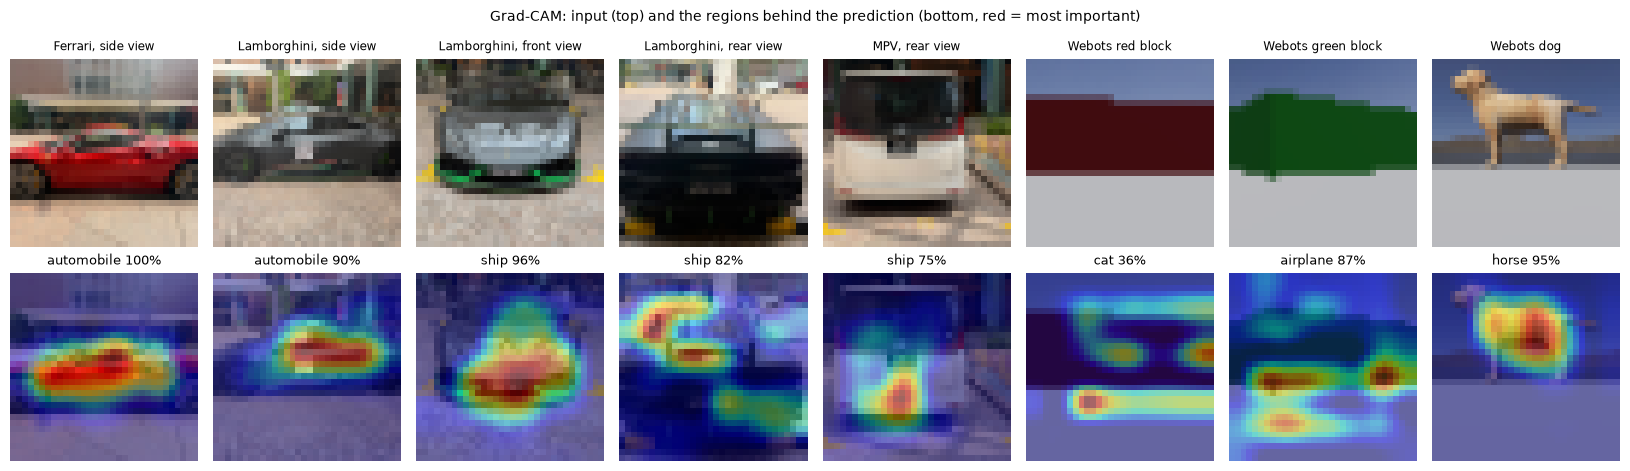

Ferrari, side view       -> automobile  100%   heatmap share in bottom third: 8%
Lamborghini, side view   -> automobile   90%   heatmap share in bottom third: 0%
Lamborghini, front view  -> ship         96%   heatmap share in bottom third: 17%
Lamborghini, rear view   -> ship         82%   heatmap share in bottom third: 24%
MPV, rear view           -> ship         75%   heatmap share in bottom third: 35%
Webots red block         -> cat          36%   heatmap share in bottom third: 23%
Webots green block       -> airplane     87%   heatmap share in bottom third: 31%
Webots dog               -> horse        95%   heatmap share in bottom third: 0%


In [2]:
CASES = [
    ("my_photos/photo_12.jpeg", "Ferrari, side view"),
    ("my_photos/photo_15.jpeg", "Lamborghini, side view"),
    ("my_photos/photo_16.jpeg", "Lamborghini, front view"),
    ("my_photos/photo_13.jpeg", "Lamborghini, rear view"),
    ("my_photos/photo_07.jpeg", "MPV, rear view"),
    ("results/webots_runs/red_block_002_cnn_input.png", "Webots red block"),
    ("results/webots_runs/green_block_003_cnn_input.png", "Webots green block"),
    ("results/webots_runs/dog_test_cnn_input.png", "Webots dog"),
]
fig, axes = plt.subplots(2, len(CASES), figsize=(2.05 * len(CASES), 4.9))
rows = []
for col, (path, title) in enumerate(CASES):
    x = load_for_cnn(path); cam, cls, p = grad_cam(x)
    # Share of the heatmap that falls in the bottom third of the image (ground / paving in these photos).
    bottom_share = cam[22:].sum() / cam.sum()
    rows.append((title, CLASS_NAMES[cls], p[cls], bottom_share))
    axes[0, col].imshow(x); axes[0, col].set_title(title, fontsize=8.5)
    axes[1, col].imshow(overlay(x, cam)); axes[1, col].set_title(f"{CLASS_NAMES[cls]} {p[cls]:.0%}", fontsize=9)
    for ax in axes[:, col]: ax.axis("off")
fig.suptitle("Grad-CAM: input (top) and the regions behind the prediction (bottom, red = most important)", fontsize=10)
plt.tight_layout(); fig.savefig(OUT / "gradcam.png", dpi=170); plt.show()
for title, label, conf, share in rows:
    print(f"{title:<24} -> {label:<10} {conf:5.0%}   heatmap share in bottom third: {share:.0%}")

## Reading the heatmaps

The printed *bottom-third share* is a rough number: how much of the heatmap lies in the lowest third of the image, which in these photos is mostly ground.
Look at the pictures first; the number only helps compare them.